# Week 9: Matching and instruments
**DS-UA 201 · Fall 2026**  
**Center for Data Science, New York University**  

**TA: Xiang Gao**

Nov 6, 2026

[Open in Colab](https://colab.research.google.com/github/xgao0o/DS-UA_201-Causal-Inference-Fall-2026/blob/main/labs/9-Matching_Instruments.ipynb) (available after publication to the repository).

All data and scenarios below are **synthetic teaching examples**, not empirical findings about college, training, or earnings. No external data files or downloads are required.


## Setup
Run cells from top to bottom, or choose **Restart Kernel and Run All Cells**. We use NumPy, pandas, Matplotlib, and statsmodels. Each simulation has a fixed seed. See the [course README](../README.md) for local setup; in Colab, upload this notebook and run all cells.

If needed, install with `python -m pip install numpy pandas matplotlib statsmodels` (use `%pip install numpy pandas matplotlib statsmodels` inside Colab).


In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import display

plt.rcParams.update({
    "figure.figsize": (7, 4), "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, ORANGE, GREEN = "#526F8A", "#B85C38", "#477766"


## 1. Matching: college and income
**Matching** compares treated and untreated people with similar pretreatment covariates. Here we use **exact matching within discrete strata**: everyone with the same $C$ belongs to the same stratum. We use all observations in each stratum, rather than selecting one control for each treated person. Averaging these comparisons to a target distribution is also called **standardization**.

Let $\Delta=Y(1)-Y(0)$. Three different population parameters are

$$\operatorname{ATE}=\mathbb E[\Delta],\qquad
\operatorname{ATT}=\mathbb E[\Delta\mid S=1],\qquad
\operatorname{ATU}=\mathbb E[\Delta\mid S=0].$$

For our matching comparisons to identify these effects, assume:

1. **Consistency, a well-defined treatment, and no interference:** $Y=Y(S)$ and one person's treatment does not change another's outcome.
2. **Conditional exchangeability:** $(Y(0),Y(1))\perp S\mid C$. Within a stratum, treatment assignment is independent of potential outcomes.
3. **Overlap:** $0<P(S=1\mid C=c)<1$ in every stratum in the target population.

The simulated rows represent independent draws from the target population. In real data, sampling and selection also need attention. Matching observed covariates does not establish the absence of unmeasured confounding.


### Parameter → identification → estimator → estimate
Define the conditional causal effect $\tau(c)=\mathbb E[Y(1)-Y(0)\mid C=c]$. Under the assumptions above,

$$\operatorname{ATE}
=\sum_c P(C=c)\tau(c)
=\sum_c P(C=c)\left\{\mathbb E[Y\mid S=1,C=c]-\mathbb E[Y\mid S=0,C=c]\right\}.$$

To estimate it, let $n_c$ be the number of sampled people in stratum $c$ and $\bar Y_{s,c}$ the sample outcome mean for treatment $s$ in that stratum:

$$\widehat{\operatorname{ATE}}_{\mathrm{match}}
=\sum_c \frac{n_c}{n}\left(\bar Y_{1,c}-\bar Y_{0,c}\right).$$

To target the ATT or ATU, replace the weights by sample stratum shares **among the treated** or **among the untreated**, respectively.


### Return to the family-resources example
As in Week 8, $C=1$ means higher family resources, $S=1$ means attending college, and $Y$ is annual income in synthetic dollars. We retain the baseline income model but deliberately let effects and attendance probabilities vary:

$$\begin{aligned}
C&\sim\operatorname{Bernoulli}(0.4),\qquad \varepsilon\sim N(0,5000^2),\quad C\perp\varepsilon,\\
Y(0)&=50000+20000C+\varepsilon,\\
Y(1)&=Y(0)+(20000+20000C),\\
P(S=1\mid C)&=0.3+0.6C.
\end{aligned}$$

Assignment uses randomness independent of $\varepsilon$. Effects are $20000$ for $C=0$ and $40000$ for $C=1$, so the population ATE is $0.6(20000)+0.4(40000)=28000$.

Week 8 used a constant $30000$ effect and attendance probabilities $0.3$ and $0.7$. Today's changes make the distinction between regression weights and population shares visible. They are teaching choices, not claims about real families. Define both potential outcomes **before** assigning treatment.


In [2]:
college_rng = np.random.default_rng(9201)
n = 2000
family = college_rng.binomial(1, 0.4, n)
noise = college_rng.normal(0, 5000, n)
y0 = 50000 + 20000 * family + noise
y1 = y0 + 20000 + 20000 * family
prob_college = 0.3 + 0.6 * family
college = college_rng.binomial(1, prob_college)
income = np.where(college == 1, y1, y0)

# The analyst observes only C, S, and Y.
college_data = pd.DataFrame({"C": family, "S": college, "Y": income})
# An oracle sees both outcomes only because we constructed this simulation.
college_truth = pd.DataFrame({"Y0": y0, "Y1": y1})
assert np.allclose(income, college * y1 + (1 - college) * y0)
display(college_data.head().round(2))


,C,S,Y
0,0,0,54476.51
1,0,1,69827.82
2,0,0,40321.30
3,1,1,104717.80
4,1,1,109035.65


### Inspect overlap, compare within strata, and average
Both treatment groups must be present before we calculate their means. A zero count is a missing comparison, not a zero treatment effect. Even a small nonzero count can make an estimate unstable.


In [3]:
counts = pd.crosstab(college_data.C, college_data.S).reindex(
    index=[0, 1], columns=[0, 1], fill_value=0)
assert (counts.to_numpy() > 0).all(), "A stratum lacks a comparison group."
means = college_data.groupby(["C", "S"]).Y.mean().unstack("S")
stratum_gaps = means[1] - means[0]
target_weights = college_data.C.value_counts(normalize=True).sort_index()
matching_ate = (target_weights * stratum_gaps).sum()
raw_gap = (college_data.loc[college_data.S == 1, "Y"].mean()
           - college_data.loc[college_data.S == 0, "Y"].mean())

matching_table = pd.DataFrame({
    "n: S=0": counts[0], "n: S=1": counts[1],
    "Mean Y: S=0": means[0], "Mean Y: S=1": means[1],
    "Difference": stratum_gaps, "ATE weight": target_weights,
})
matching_table.index.name = "Family resources C"
display(matching_table.round(3))
print(f"Raw treated-minus-untreated gap: ${raw_gap:,.2f}")
print(f"Matching ATE estimate:          ${matching_ate:,.2f}")


,n: S=0,n: S=1,Mean Y: S=0,Mean Y: S=1,Difference,ATE weight
Family resources C,,,,,,
0,863,329,49856.968,70149.073,20292.105,0.596
1,76,732,70149.670,110001.734,39852.064,0.404


Raw treated-minus-untreated gap: $46,144.63
Matching ATE estimate:          $28,194.33


In [12]:
# Changing the target weights changes which average effect we estimate.
sample_weights = pd.DataFrame({
    "ATE": target_weights,
    "ATT": counts[1] / counts[1].sum(),
    "ATU": counts[0] / counts[0].sum(),
})
matching_estimates = sample_weights.mul(stratum_gaps, axis=0).sum()

# These population quantities are known from the simulation design.
pop_shares = np.array([0.6, 0.4])
pop_propensity = np.array([0.3, 0.9])
pop_effects = np.array([20000., 40000.])
pop_treated_shares = pop_shares * pop_propensity
pop_treated_shares /= pop_treated_shares.sum()
pop_untreated_shares = pop_shares * (1 - pop_propensity)
pop_untreated_shares /= pop_untreated_shares.sum()
population_targets = pd.Series({
    "ATE": pop_shares @ pop_effects,
    "ATT": pop_treated_shares @ pop_effects,
    "ATU": pop_untreated_shares @ pop_effects,
})
effects = college_truth.Y1 - college_truth.Y0
finite_targets = pd.Series({
    "ATE": effects.mean(),
    "ATT": effects[college == 1].mean(),
    "ATU": effects[college == 0].mean(),
})
display(pd.DataFrame({
    "Population parameter": population_targets,
    "Finite-group oracle average": finite_targets,
    "Matching estimate": matching_estimates,
}).round(2))


,Population parameter,Finite-group oracle average,Matching estimate
ATE,28000.00,28080.00,28194.33
ATT,33333.33,33798.30,33786.82
ATU,21739.13,21618.74,21875.23


The oracle column uses both potential outcomes; the matching estimates use only observed data. The finite groups have random compositions, and treatment groups have different average noise by chance. Neither column must equal the population parameter exactly.

### Exercise 1: choose the target and diagnose a missing comparison
1. Why does the ATT exceed the ATE in this population?
2. Use `sample_weights` and `stratum_gaps` to reconstruct the ATT estimate.
3. If every higher-resource person attended college, could this matching procedure recover the full-population ATE?

<details><summary>Answer</summary>
<ol>
<li>Higher-resource people have the larger effect and are overrepresented among attendees: their population share is $0.36/0.54=2/3$ among the treated, compared with $0.4$ overall. Thus the ATT is about $33333.33$, while the ATE is $28000$.</li>
<li>Run <code>(sample_weights["ATT"] * stratum_gaps).sum()</code>. Use treated-group shares, not the overall shares or equal weights.</li>
<li>No. There would be no untreated observations in the $C=1$ stratum. Under a population rule $P(S=1\mid C=1)=1$, overlap fails; if this happens only by chance in a sample, the sample still lacks the needed comparison. Silently dropping that stratum changes the target population.</li>
</ol>

</details>


## 2. Regression uses different weights
Fit $Y_i=\alpha+\beta S_i+\gamma C_i+e_i$. Because $C$ is binary, an intercept and $C$ give a separate intercept for each stratum. There is still only **one common treatment coefficient**.

For a regression with a full set of stratum indicators and a common treatment coefficient,

$$\beta=\sum_c w_c\tau(c),\qquad
w_c=\frac{P(C=c)e_c(1-e_c)}{\sum_k P(C=k)e_k(1-e_k)},\qquad
e_c=P(S=1\mid C=c).$$

The causal interpretation uses conditional exchangeability and consistency. The regression weighting identity itself is algebraic: without these assumptions it weights conditional **associations**. The formula is not a general claim about arbitrary linear controls; multiple covariates require indicators for their joint strata to obtain this result.

Here $e_c(1-e_c)=\operatorname{Var}(S\mid C=c)$. For a given stratum size, more treatment variation gives more weight. Both **size and variation** matter. In a sample, replace $P(C=c)$ with $n_c/n$ and $e_c$ with $\widehat e_c=n_{1c}/n_c$:

$$\widehat\beta=\sum_c\widehat w_c(\bar Y_{1,c}-\bar Y_{0,c}),\qquad
\widehat w_c=\frac{n_c\widehat e_c(1-\widehat e_c)}{\sum_k n_k\widehat e_k(1-\widehat e_k)}.$$

Use the empirical variance with divisor $n_c$, equivalent to `var(ddof=0)`, in this identity. The usual `pandas.var()` default uses divisor $n_c-1$.


In [13]:
adjusted_fit = smf.ols("Y ~ S + C", data=college_data).fit()
propensity_hat = counts[1] / counts.sum(axis=1)
treatment_variance = propensity_hat * (1 - propensity_hat)
regression_mass = counts.sum(axis=1) * treatment_variance
regression_weights = regression_mass / regression_mass.sum()
ols_from_weights = (regression_weights * stratum_gaps).sum()

assert np.isclose(ols_from_weights, adjusted_fit.params["S"])
assert np.allclose(treatment_variance,
                   college_data.groupby("C").S.var(ddof=0))
weight_table = pd.DataFrame({
    "Treatment share": propensity_hat,
    "Treatment variance": treatment_variance,
    "Matching ATE weight": target_weights,
    "OLS weight": regression_weights,
})
display(weight_table.round(4))
print(f"OLS coefficient on S:         ${adjusted_fit.params['S']:,.2f}")
print(f"Same coefficient via weights: ${ols_from_weights:,.2f}")
print(f"Matching ATE estimate:        ${matching_ate:,.2f}")

pop_ols_weights = pop_shares * pop_propensity * (1 - pop_propensity)
pop_ols_weights /= pop_ols_weights.sum()
pop_ols_target = pop_ols_weights @ pop_effects
print(f"Population OLS target:        ${pop_ols_target:,.2f}")
print(f"Population ATE:               ${population_targets['ATE']:,.2f}")


,Treatment share,Treatment variance,Matching ATE weight,OLS weight
0,0.2760,0.1998,0.596,0.7758
1,0.9059,0.0852,0.404,0.2242


OLS coefficient on S:         $24,678.21
Same coefficient via weights: $24,678.21
Matching ATE estimate:        $28,194.33
Population OLS target:        $24,444.44
Population ATE:               $28,000.00


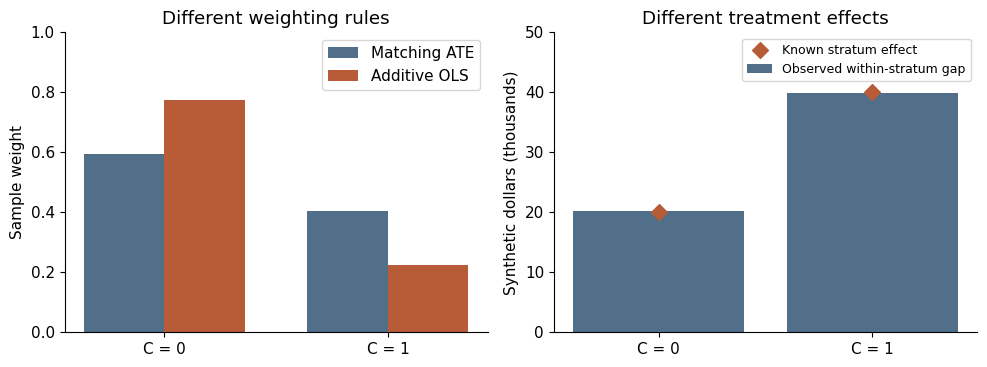

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
positions = np.arange(2)
axes[0].bar(positions - 0.18, target_weights, width=0.36,
            label="Matching ATE", color=BLUE)
axes[0].bar(positions + 0.18, regression_weights, width=0.36,
            label="Additive OLS", color=ORANGE)
axes[0].set(xticks=positions, xticklabels=["C = 0", "C = 1"],
            ylabel="Sample weight", ylim=(0, 1), title="Different weighting rules")
axes[0].legend()
axes[1].bar(positions, stratum_gaps / 1000, color=BLUE,
            label="Observed within-stratum gap")
axes[1].scatter(positions, pop_effects / 1000, marker="D", s=65,
                color=ORANGE, zorder=3, label="Known stratum effect")
axes[1].set(xticks=positions, xticklabels=["C = 0", "C = 1"],
            ylabel="Synthetic dollars (thousands)", ylim=(0, 50),
            title="Different treatment effects")
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()


The higher-resource stratum has a larger effect but little treatment variation: almost everyone attends college. The common OLS coefficient therefore puts less weight on it.

### Exercise 2: when do the targets agree?
1. What happens to the two population targets if every person's effect is $30000$?

<details><summary>Answer</summary>
<ol>
<li>Every weighted average of the constant effect is $30000$. Finite-sample estimates can still differ because their weights apply to noisy stratum comparisons.</li>
</ol>

</details>


## 3. The curse of dimensionality
With $k$ binary controls, there are up to $2^k$ joint strata. If continuous control $j$ is divided into $b_j$ bins, there are up to $\prod_j b_j$ joint strata, not just the number of bins for one variable.

A stratum with one observation cannot contain both treatment groups. Wider bins may improve counts but compare less similar people and leave residual confounding. Dropping unmatched observations changes the population represented by the analysis.

The next simulation deliberately randomizes treatment with probability $0.5$, so **population overlap holds**. Nevertheless, exact matches become scarce in a fixed sample as we add independent binary controls. This illustrates sample sparsity, which is distinct from a population rule that makes treatment deterministic.


In [15]:
dimension_rng = np.random.default_rng(9202)
dimension_n = 1000
controls = dimension_rng.binomial(1, 0.5, size=(dimension_n, 12))
dimension_treatment = dimension_rng.binomial(1, 0.5, dimension_n)
dimension_rows = []
for k in [1, 4, 8, 12]:
    # Encode each vector of k binary controls as a stratum identifier.
    stratum_id = controls[:, :k] @ (2 ** np.arange(k))
    tab = pd.crosstab(stratum_id, dimension_treatment).reindex(
        columns=[0, 1], fill_value=0)
    has_both = (tab[0] > 0) & (tab[1] > 0)
    fraction_matched = tab.loc[has_both].to_numpy().sum() / dimension_n
    dimension_rows.append({
        "Binary controls": k, "Possible strata": 2 ** k,
        "Observed strata": len(tab), "Strata with both arms": has_both.sum(),
        "% people with an opposite-arm match": 100 * fraction_matched,
    })
display(pd.DataFrame(dimension_rows).set_index("Binary controls").round(1))


,Possible strata,Observed strata,Strata with both arms,% people with an opposite-arm match
Binary controls,,,,
1,2,2,2,100.0
4,16,16,16,100.0
8,256,252,195,87.4
12,4096,895,53,11.2


### Exercise 3: a matching tradeoff
You have five continuous controls and use four bins for each. How many joint strata are possible? Why is dropping poorly matched people not automatically a solution for the original ATE?

<details><summary>Answer</summary>
<p>There are $4^5=1024$ possible strata. Removing unmatched people may leave a comparison for a narrower population, but does not identify effects for the excluded people. Report who remains and define the new target. Coarsening bins also requires judging whether the remaining within-bin differences matter for confounding. A larger sample can help sparsity when population overlap holds; it cannot repair deterministic treatment in a stratum.</p>

</details>


## 4. Instruments, assumptions, and compliance types
### When observed controls are not enough
Matching relies on measuring a sufficient set of controls. If an unobserved variable $U$ affects both treatment and outcome after adjustment, matching on the available controls may still be confounded.

An **instrument** $Z$ provides a different source of treatment variation. Consider a hypothetical randomized invitation to a training program:

- $Z=1$: invited; $Z=0$: not invited.
- $S=1$: participates in training; $S=0$: does not participate.
- $Y$: later annual earnings.
- $U$: unobserved characteristics affecting participation and earnings.

People can access training without an invitation, and some invited people decline. Thus the invitation is randomized but participation is not. IV uses variation in participation induced by the invitation.

The graph below depicts the proposed mechanism. Its missing paths are substantive assumptions: in particular, no direct $Z\to Y$ arrow and no common cause of $Z$ and $U$.


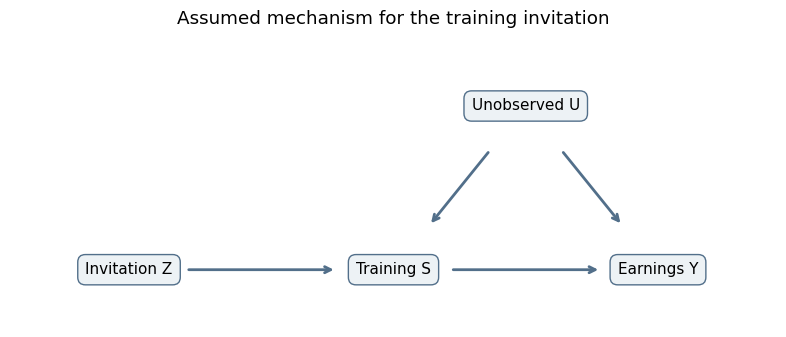

In [20]:
fig, ax = plt.subplots(figsize=(8, 3.5))
nodes = {"Invitation Z": (0, 0), "Training S": (1, 0),
         "Earnings Y": (2, 0), "Unobserved U": (1.5, 1)}
edges = [("Invitation Z", "Training S"), ("Training S", "Earnings Y"),
         ("Unobserved U", "Training S"), ("Unobserved U", "Earnings Y")]
for start, end in edges:
    ax.annotate("", xy=nodes[end], xytext=nodes[start],
                arrowprops=dict(arrowstyle="->", color=BLUE, lw=2,
                                shrinkA=43, shrinkB=43))
for label, (x, y) in nodes.items():
    ax.text(x, y, label, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.5", fc="#EDF2F5", ec=BLUE))
ax.set(xlim=(-0.45, 2.45), ylim=(-0.35, 1.45),
       title="Assumed mechanism for the training invitation")
ax.axis("off")
fig.tight_layout()
plt.show()


### Four assumptions for the binary-IV LATE interpretation
Define $S_i(z)$ as person $i$'s treatment status under invitation $z$, and $Y_i(s,z)$ as earnings under treatment $s$ and invitation $z$. These describe interventions, not conditioning on observed groups. We also require consistency, well-defined interventions, no interference, and both values of $Z$ in the population.

1. **Independence of the instrument:** the invitation is independent of all potential treatment statuses and potential outcomes. Random assignment provides this in our example. It does **not** imply that actual training participation is randomized.
2. **Exclusion restriction:** $Y_i(s,1)=Y_i(s,0)$ for each $s$. Holding training fixed, the invitation does not affect earnings. We can then write $Y_i(s)$ without $z$. For example, an invitation that also supplies useful job-search advice could violate exclusion.
3. **Relevance:** $\mathbb E[S\mid Z=1]-\mathbb E[S\mid Z=0]\ne0$. The instrument changes treatment uptake in the population. This is not defined by a sample p-value; a tiny first stage can produce unstable estimates.
4. **Monotonicity:** $S_i(1)\ge S_i(0)$ for every person. With this orientation, no one participates only when *not* invited. Equality is allowed: the invitation need not change everyone's treatment.

Under exclusion, a compact form of independence is

$$Z\perp\big(Y(0),Y(1),S(0),S(1)\big).$$

Independence and exclusion are separate: randomizing an invitation does not prevent a direct effect of its contents on earnings. A strong first stage does not establish either assumption. In an observational IV design, independence may instead be argued conditional on baseline controls, requiring a corresponding adjusted analysis.


### Four compliance types
Each person has two potential treatment statuses, although we observe only $S_i=S_i(Z_i)$.

| Type | $S_i(0)$ | $S_i(1)$ | Response to invitation |
|:--|--:|--:|:--|
| Never-taker | 0 | 0 | Does not participate either way |
| Complier | 0 | 1 | Participates if invited |
| Always-taker | 1 | 1 | Participates either way |
| Defier | 1 | 0 | Participates only if not invited |

Monotonicity excludes defiers. It allows always-takers and never-takers. **Complier** describes a counterfactual response to this particular instrument, not a person's general cooperativeness. Seeing $Z=1,S=1$ does not tell us whether someone is a complier or an always-taker.

The **local average treatment effect** is

$$\operatorname{LATE}=\mathbb E[Y(1)-Y(0)\mid S(1)>S(0)].$$

It is the average effect for people whose treatment changes because of the instrument. It need not equal the ATE or ATT. Another instrument may affect different people and identify a different LATE. The foundational reference is [Angrist, Imbens, and Rubin (1996)](https://dash.harvard.edu/entities/publication/73120378-82c1-6bd4-e053-0100007fdf3b).


### Exercise 4: assumptions and types
1. A person would train whether or not invited. Does this violate monotonicity?
2. An invited participant is labeled a complier from the observed data alone. Is that justified?
3. The randomized invitation includes job leads that improve earnings even without training. Which assumption fails?

<details><summary>Answer</summary>
<ol>
<li>No. This is an always-taker with $S(0)=S(1)=1$. Monotonicity is a weak inequality.</li>
<li>No. The person could be a complier or an always-taker. We do not observe what they would do without the invitation.</li>
<li>Exclusion fails: the invitation has an earnings pathway outside training. Independence can still hold because the invitation was randomized. Randomization identifies the effect of the invitation, but the IV ratio need not identify the effect of training on compliers.</li>
</ol>

</details>
